# Wizualizacja konfiguracji z `generate_datasets.py`

Małe (głównie 2D) odpowiedniki zbiorów z `src/data_generate/generate_datasets.py`, generowane w pamięci (nic nie jest zapisywane).
Każda sekcja pokazuje jedną własność, którą testuje dana grupa konfiguracji. Parametry różnicujące są takie same jak w skrypcie, reszta jest zmniejszona, żeby dało się to narysować.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_friedman1, make_regression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier

sys.path.append(str(Path.cwd().parent))
from config import SEED

In [2]:
CATEGORY_LABELS = ["a", "b", "c", "d", "e"]


def scatter(X, y, ax, title, palette="Set2"):
    # rzadsze klasy (wyższe etykiety) rysowane na wierzchu
    idx = np.argsort(y, kind="stable")
    sns.scatterplot(x=X[idx, 0], y=X[idx, 1], hue=y[idx], palette=palette, s=14, alpha=0.8, linewidth=0, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("f0")
    ax.set_ylabel("f1")

## 1. Bazowe: `binary_small`, `multi_small`, `reg_small`

Czysty punkt odniesienia dla pozostałych sekcji.

- `*_large` (`binary_large`, `multi_large`, `reg_large`) to te same dane, tylko więcej próbek i cech: nie testują innej własności, więc nie mają osobnego wykresu.
- `*_check` (`binary_check`, `multi_check`, `reg_check`) to mało cech, z których **każda** jest informatywna (`n_redundant=0`), czyli prosty test poprawności. Wizualnie wygląda jak zbiór bazowy.

Tu `n_clusters_per_class=1` dla czytelności (w skrypcie domyślnie 2).

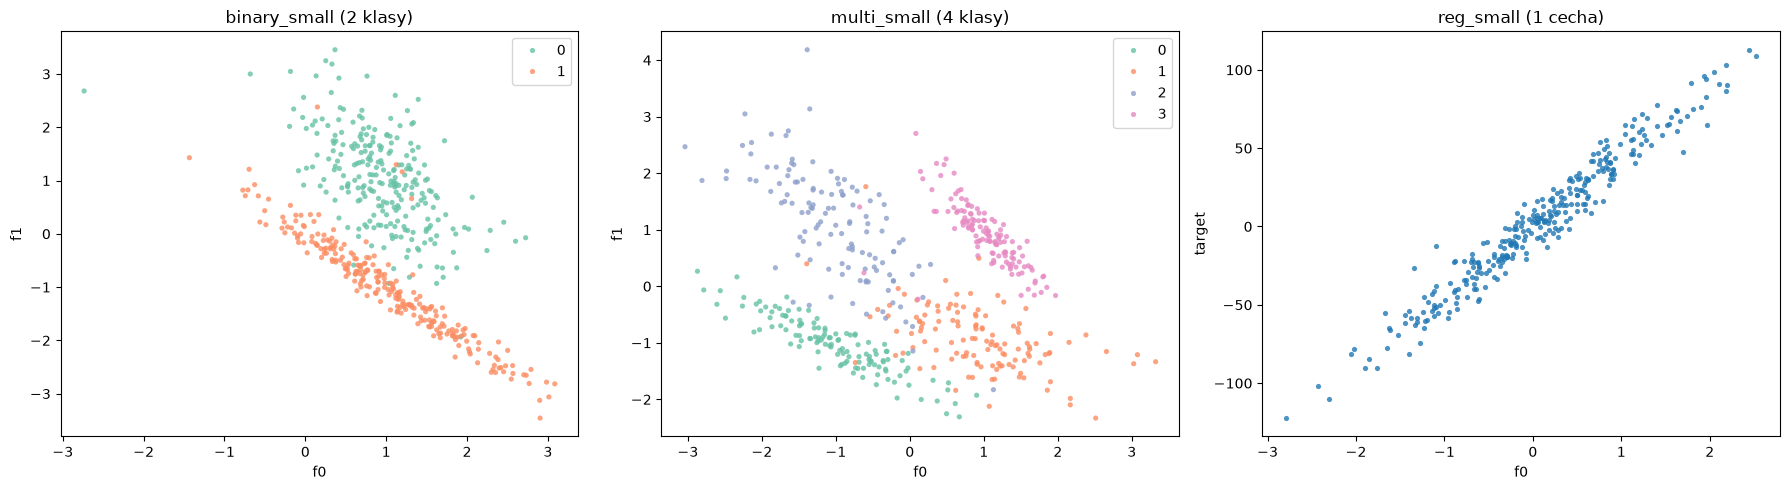

In [3]:
X_bin, y_bin = make_classification(n_samples=500, n_features=2, n_informative=2, n_redundant=0, n_classes=2,
                                   n_clusters_per_class=1, flip_y=0.02, random_state=SEED)
X_multi, y_multi = make_classification(n_samples=500, n_features=2, n_informative=2, n_redundant=0, n_classes=4,
                                       n_clusters_per_class=1, flip_y=0.02, random_state=SEED)
X_reg, y_reg = make_regression(n_samples=300, n_features=1, n_informative=1, noise=10.0, random_state=SEED)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
scatter(X_bin, y_bin, axes[0], "binary_small (2 klasy)")
scatter(X_multi, y_multi, axes[1], "multi_small (4 klasy)")
sns.scatterplot(x=X_reg[:, 0], y=y_reg, s=14, alpha=0.8, linewidth=0, ax=axes[2])
axes[2].set_title("reg_small (1 cecha)")
axes[2].set_xlabel("f0")
axes[2].set_ylabel("target")
plt.tight_layout()
plt.show()

## 2. Cechy informatywne vs redundantne: `n_redundant` (`*_small` vs `*_check`)

Cecha redundantna to liniowa kombinacja cech informatywnych: nie wnosi nowej informacji, ale jest silnie skorelowana z pozostałymi.
Tu `f0`, `f1` są informatywne, `f2` redundantna (`shuffle=False`; w skrypcie kolumny są przetasowane, więc redundantne są wymieszane z resztą).
Na wykresach z `f2` punkty układają się w równie dobrze rozdzielone chmury, a regresja `f2` na `f0`, `f1` daje błąd ≈ 0.

f2 = 0.488*f0 + 0.181*f1 + 0.000, max |błąd| = 2.22e-16


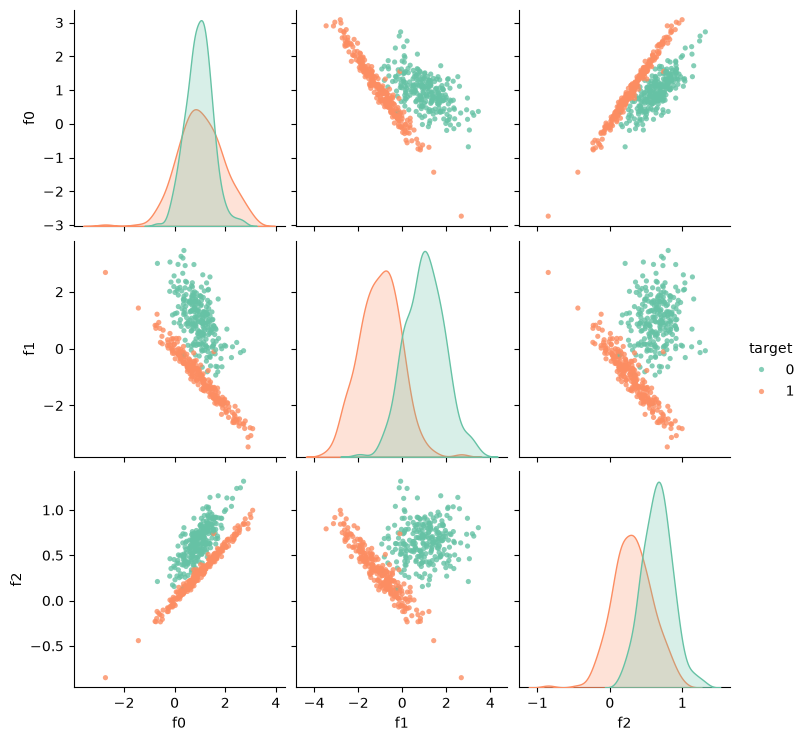

In [4]:
X, y = make_classification(n_samples=500, n_features=3, n_informative=2, n_redundant=1, n_classes=2,
                           n_clusters_per_class=1, shuffle=False, random_state=SEED)
df = pd.DataFrame(X).add_prefix("f")
df["target"] = y

A = np.c_[X[:, :2], np.ones(len(X))]
coef, *_ = np.linalg.lstsq(A, X[:, 2])
print(f"f2 = {coef[0]:.3f}*f0 + {coef[1]:.3f}*f1 + {coef[2]:.3f}, max |błąd| = {np.abs(A @ coef - X[:, 2]).max():.2e}")

sns.pairplot(df, hue="target", palette="Set2", plot_kws={"s": 14, "alpha": 0.8, "linewidth": 0})
plt.show()

## 3. Cechy kategoryczne: `CATEGORICAL_FEATURES` (`*_multi_features`)

W `*_multi_features` pierwsze 20 kolumn jest zamienianych przez `pd.qcut` na 5 kategorii `a`–`e` (kwantyle, więc kategorie są równoliczne).
Ciągła cecha traci szczegóły: wszystkie punkty z jednego przedziału dostają tę samą wartość.
Poza tym `multi_features` dodaje po prostu więcej wymiarów (100 cech, 50 informatywnych).

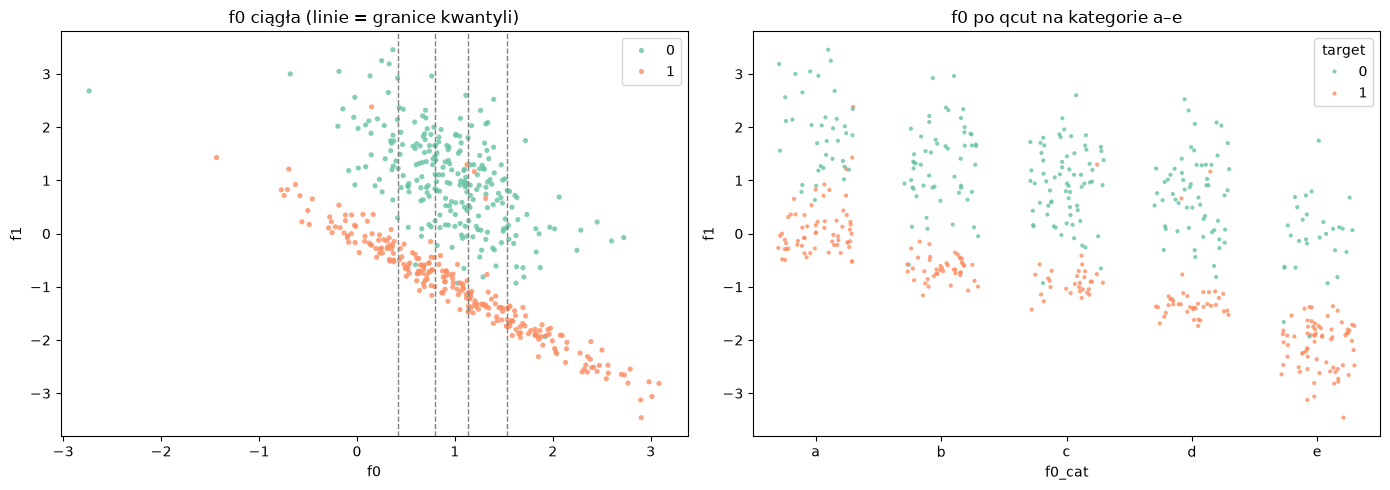

In [5]:
df = pd.DataFrame(X_bin).add_prefix("f")
df["target"] = y_bin
df["f0_cat"], edges = pd.qcut(df["f0"], q=len(CATEGORY_LABELS), labels=CATEGORY_LABELS, retbins=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter(X_bin, y_bin, axes[0], "f0 ciągła (linie = granice kwantyli)")
for e in edges[1:-1]:
    axes[0].axvline(e, color="grey", linestyle="--", linewidth=1)
sns.stripplot(data=df, x="f0_cat", y="f1", hue="target", palette="Set2", size=3, alpha=0.8, jitter=0.3, ax=axes[1])
axes[1].set_title("f0 po qcut na kategorie a–e")
plt.tight_layout()
plt.show()

## 4. Niezbalansowanie: `imbalanced`, `rare_event`, `multi_imbalanced`, `multi_rare_class`

Ten sam układ danych, różne `weights`. Przy `[0.995, 0.005]` klasa pozytywna to kilka punktów na 2000, więc model, który zawsze zwraca klasę 0, ma 99.5% accuracy.
Tu `flip_y=0`, żeby proporcje były dokładne (w skrypcie `imbalanced` ma `flip_y=0.02`, co dokłada trochę losowych etykiet).

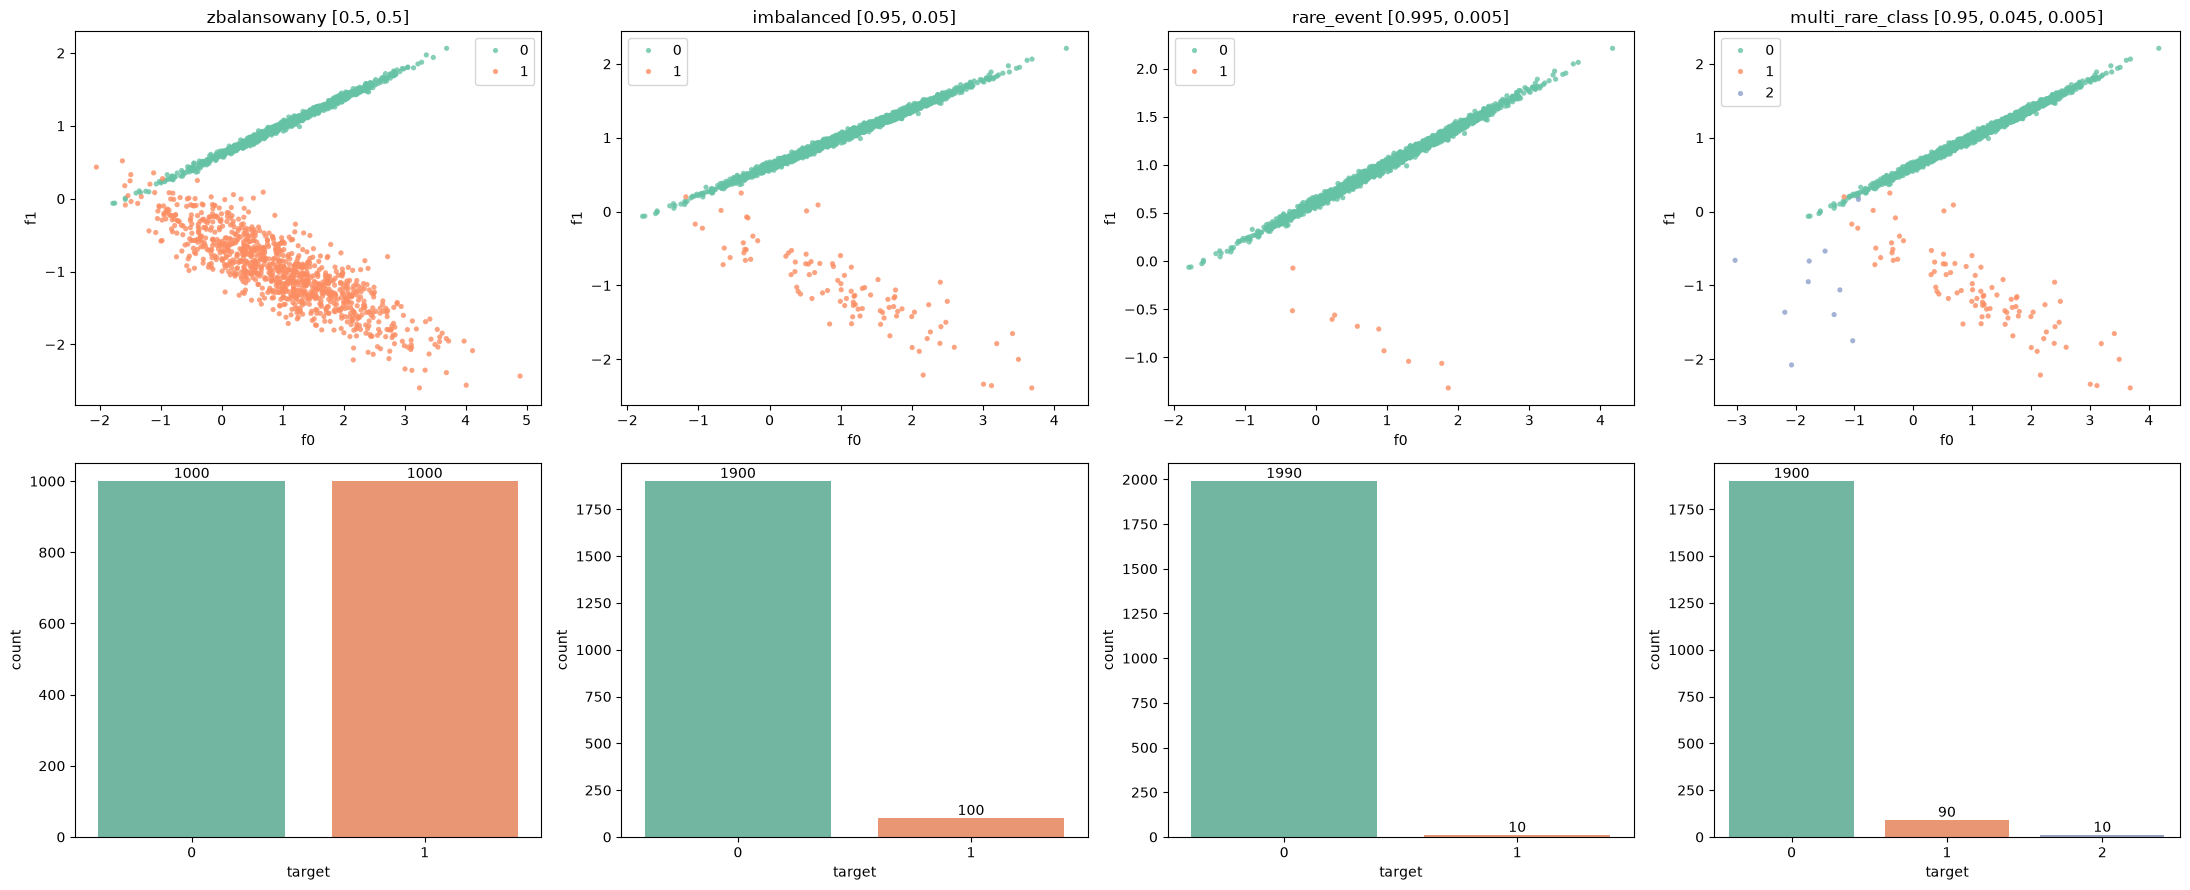

In [6]:
CONFIGS = {
    "zbalansowany [0.5, 0.5]": [0.5, 0.5],
    "imbalanced [0.95, 0.05]": [0.95, 0.05],
    "rare_event [0.995, 0.005]": [0.995, 0.005],
    "multi_rare_class [0.95, 0.045, 0.005]": [0.95, 0.045, 0.005],
}

fig, axes = plt.subplots(2, len(CONFIGS), figsize=(22, 9))
for (name, weights), ax_top, ax_bottom in zip(CONFIGS.items(), axes[0], axes[1]):
    X, y = make_classification(n_samples=2_000, n_features=2, n_informative=2, n_redundant=0, n_classes=len(weights),
                               n_clusters_per_class=1, weights=weights, flip_y=0.0, random_state=SEED)
    scatter(X, y, ax_top, name)
    sns.countplot(x=y, hue=y, palette="Set2", legend=False, ax=ax_bottom)
    for c in ax_bottom.containers:
        ax_bottom.bar_label(c)
    ax_bottom.set_xlabel("target")
plt.tight_layout()
plt.show()

## 5. Szum w etykietach: `noisy_labels`, `multi_noisy_labels`

Te same punkty, `flip_y=0.02` vs `flip_y=0.25`. `flip_y` losuje nową etykietę dla takiego odsetka próbek, więc przy 2 klasach faktycznie zmienia się ok. połowa z nich (~12.5%).
Czarne krzyżyki to próbki ze zmienioną etykietą względem `flip_y=0`. Model nie może ich nauczyć się poprawnie, więc mają wpływ głównie na dopasowanie (overfitting).

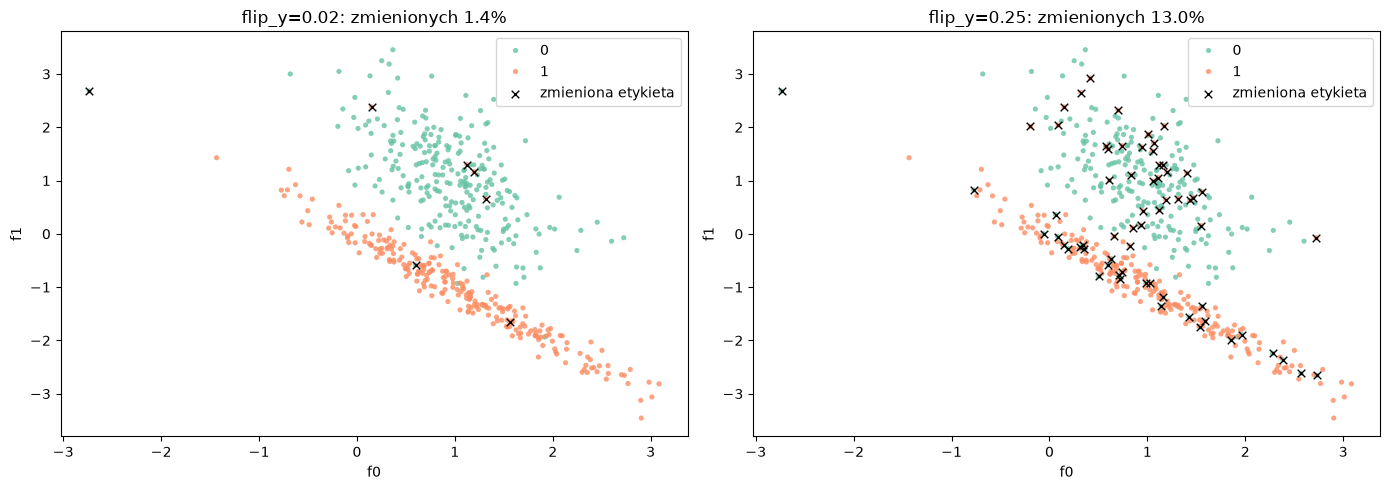

In [7]:
params = dict(n_samples=500, n_features=2, n_informative=2, n_redundant=0, n_classes=2, n_clusters_per_class=1,
              shuffle=False, random_state=SEED)
X, y_clean = make_classification(**params, flip_y=0.0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, flip in zip(axes, [0.02, 0.25]):
    _, y = make_classification(**params, flip_y=flip)
    flipped = y != y_clean
    scatter(X, y, ax, f"flip_y={flip}: zmienionych {flipped.mean():.1%}")
    ax.scatter(X[flipped, 0], X[flipped, 1], marker="x", color="black", s=30, linewidth=1, label="zmieniona etykieta")
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Trudny, nieliniowy podział: `hard_nonlinear`, `multi_hard_nonlinear`

`n_clusters_per_class > 1` rozkłada każdą klasę na kilka skupisk w rogach hiperkostki, a mniejsze `class_sep` je do siebie zbliża.
Środkowy wykres: skupiska dobrze odsunięte, widać, że każda klasa składa się z dwóch rozłącznych skupisk. Prawy: to samo przy `class_sep=0.5` jak w skrypcie, skupiska się nakładają.
W tytułach: accuracy (5-fold CV) modelu liniowego (regresja logistyczna) i nieliniowego (kNN).

W 2D mieszczą się co najwyżej 2 skupiska na klasę (`n_classes * n_clusters_per_class <= 2**n_informative`) i często da się je jeszcze rozdzielić prostą (środkowy wykres).
Nieliniowość widać dopiero w pełnej konfiguracji `hard_nonlinear` (6 skupisk na klasę w 6 wymiarach, wynik pod wykresem): model liniowy wyraźnie przegrywa z kNN.

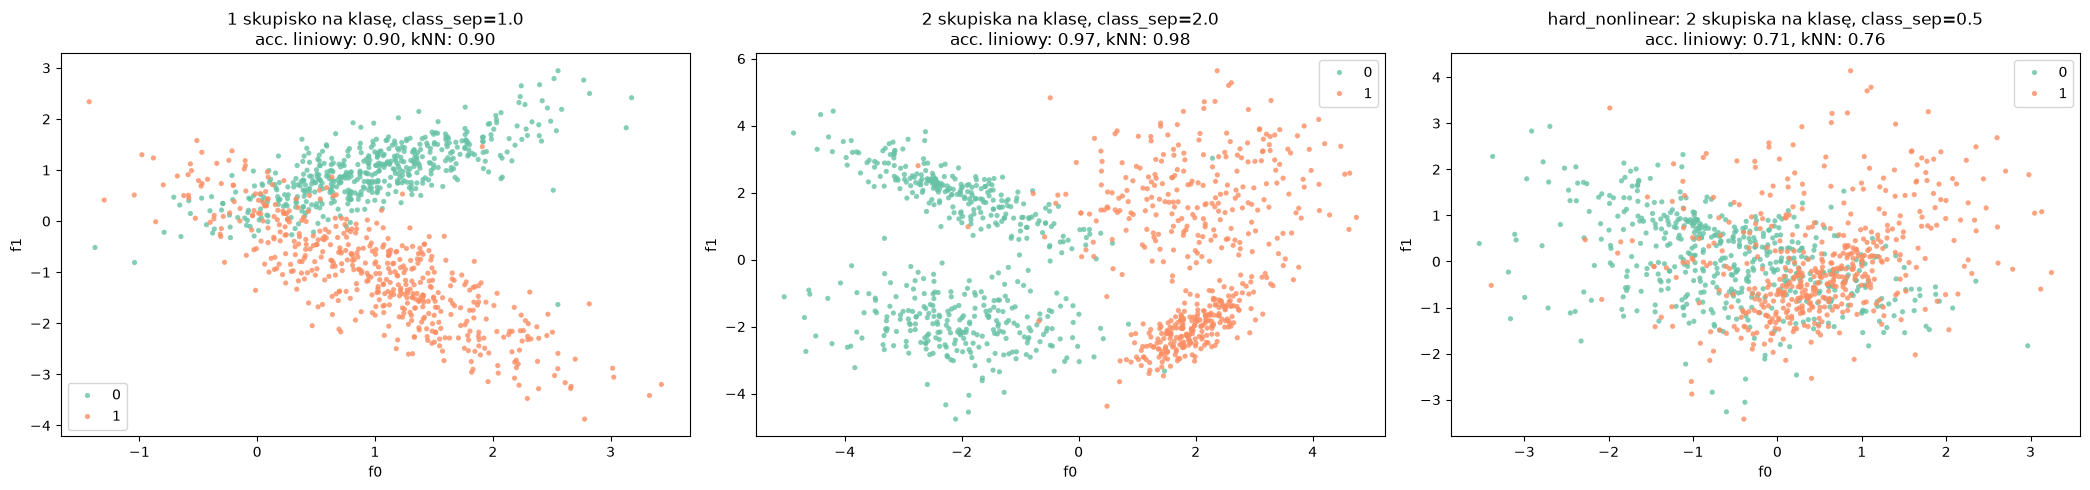

pełna konfiguracja hard_nonlinear (n=2000): acc. liniowy: 0.644, kNN: 0.742


In [8]:
def cv_acc(X, y):
    return (cross_val_score(LogisticRegression(), X, y, cv=5).mean(),
            cross_val_score(KNeighborsClassifier(n_neighbors=15), X, y, cv=5).mean())


CONFIGS = {
    "1 skupisko na klasę, class_sep=1.0": dict(n_clusters_per_class=1, class_sep=1.0),
    "2 skupiska na klasę, class_sep=2.0": dict(n_clusters_per_class=2, class_sep=2.0),
    "hard_nonlinear: 2 skupiska na klasę, class_sep=0.5": dict(n_clusters_per_class=2, class_sep=0.5),
}

fig, axes = plt.subplots(1, len(CONFIGS), figsize=(21, 5))
for (name, cfg), ax in zip(CONFIGS.items(), axes):
    X, y = make_classification(n_samples=1_000, n_features=2, n_informative=2, n_redundant=0, n_classes=2,
                               **cfg, random_state=SEED)
    lr, knn = cv_acc(X, y)
    scatter(X, y, ax, f"{name}\nacc. liniowy: {lr:.2f}, kNN: {knn:.2f}")
plt.tight_layout()
plt.show()

X, y = make_classification(n_samples=2_000, n_features=10, n_informative=6, n_redundant=0, n_classes=2,
                           n_clusters_per_class=6, class_sep=0.5, random_state=SEED)
lr, knn = cv_acc(X, y)
print(f"pełna konfiguracja hard_nonlinear (n=2000): acc. liniowy: {lr:.3f}, kNN: {knn:.3f}")

## 7. Więcej cech niż próbek (p > n): `wide_p_gt_n`, `multi_wide_p_gt_n`, `reg_wide_p_gt_n`

5 cech informatywnych + 195 cech czystego szumu. Wykres pokazuje 20 cech najsilniej skorelowanych z targetem (|corr|), kolor mówi, czy cecha jest informatywna.
Przy n=1000 szum ma korelację bliską 0, więc cechy informatywne są na samej górze. Przy n=30 (p > n) wiele cech szumu jest przypadkiem skorelowanych z targetem tak samo mocno jak prawdziwe i miesza się z nimi w rankingu, więc model łatwo się do nich dopasuje (overfitting).

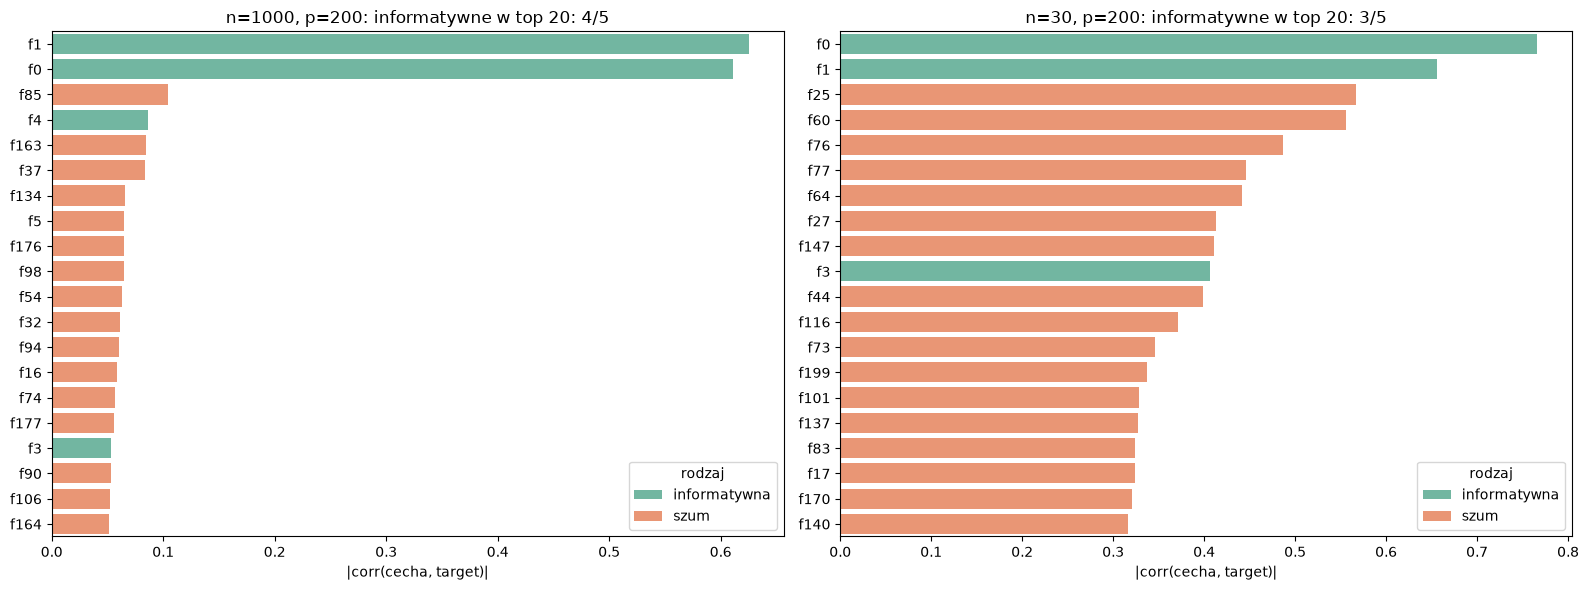

In [9]:
N_INFORMATIVE = 5

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, n in zip(axes, [1_000, 30]):
    X, y = make_classification(n_samples=n, n_features=200, n_informative=N_INFORMATIVE, n_redundant=0, n_classes=2,
                               n_clusters_per_class=1, shuffle=False, random_state=SEED)
    corr = pd.Series(np.abs([np.corrcoef(X[:, j], y)[0, 1] for j in range(X.shape[1])])).add_prefix("f")
    top = corr.sort_values(ascending=False).head(20).rename("corr").reset_index()
    top["rodzaj"] = np.where(top["index"].str[1:].astype(int) < N_INFORMATIVE, "informatywna", "szum")
    sns.barplot(data=top, x="corr", y="index", hue="rodzaj", hue_order=["informatywna", "szum"], palette="Set2",
                dodge=False, ax=ax)
    ax.set_title(f"n={n}, p=200: informatywne w top 20: {(top['rodzaj'] == 'informatywna').sum()}/{N_INFORMATIVE}")
    ax.set_xlabel("|corr(cecha, target)|")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 8. Współliniowe i nieprzeskalowane cechy: `collinear_unscaled`, `multi_collinear_unscaled`

`n_redundant` to kombinacje liniowe cech informatywnych, `n_repeated` to ich dokładne kopie, a `shift=None, scale=None` przesuwa każdą cechę o losową wartość i mnoży przez losową skalę z przedziału [1, 101].
Lewy wykres: zakresy cech różnią się o rzędy wielkości (ma to znaczenie dla modeli wrażliwych na skalę). Prawy: korelacje bliskie ±1, a kopie (`rep*`) mają r = 1 z oryginałem.

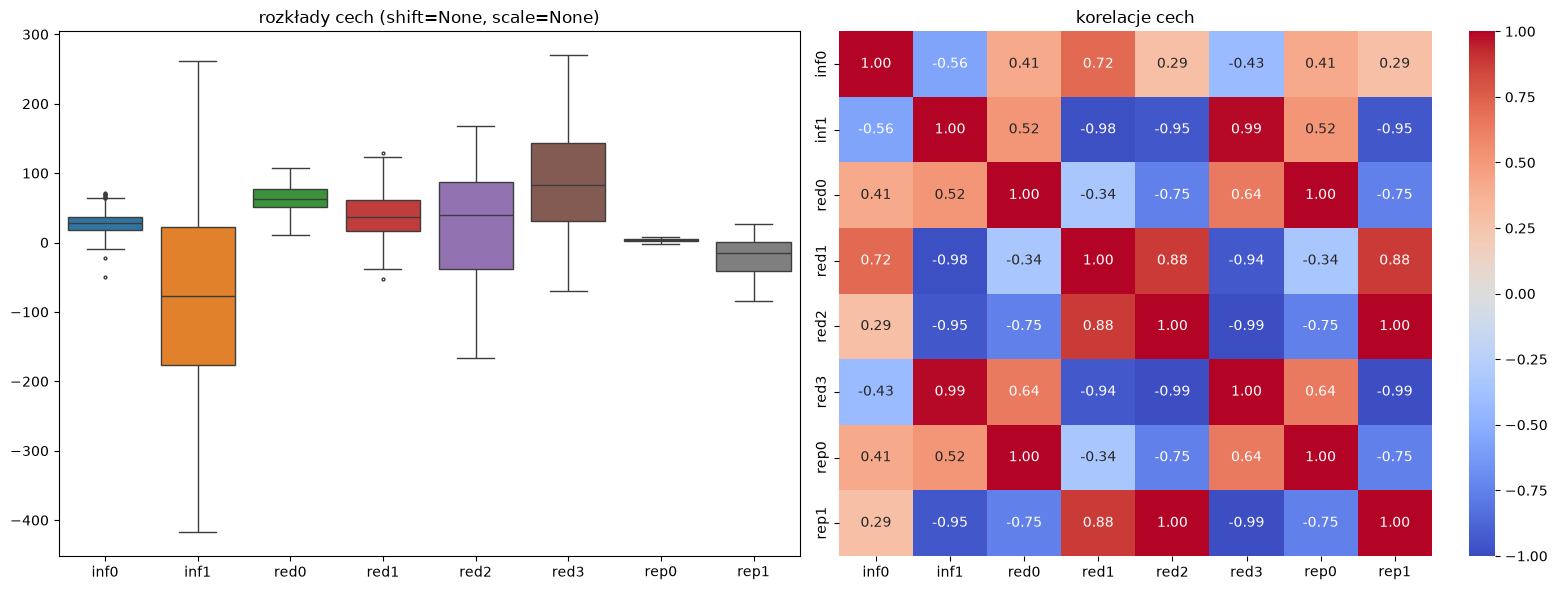

In [10]:
X, y = make_classification(n_samples=500, n_features=8, n_informative=2, n_redundant=4, n_repeated=2, n_classes=2,
                           n_clusters_per_class=1, shift=None, scale=None, shuffle=False, random_state=SEED)
df = pd.DataFrame(X, columns=["inf0", "inf1", "red0", "red1", "red2", "red3", "rep0", "rep1"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df, ax=axes[0], flierprops={"markersize": 2})
axes[0].set_title("rozkłady cech (shift=None, scale=None)")
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("korelacje cech")
plt.tight_layout()
plt.show()

## 9. Wartości odstające: `outliers`, `multi_outliers`, `reg_outliers`

Taki sam kod wstrzykiwania jak w skrypcie: 2% wierszy dostaje szum `N(0, 10·std cechy)`. Zaburzane są tylko cechy, etykiety/target zostają bez zmian.
W regresji daje to punkty daleko na osi X z „normalnym” targetem, które mocno ciągną dopasowanie liniowe.

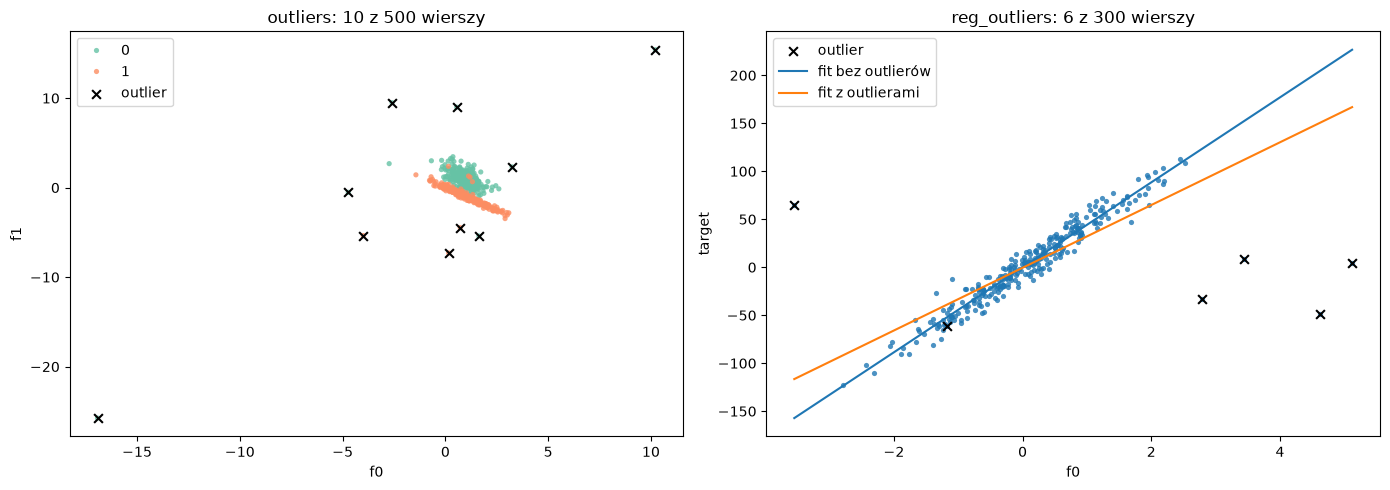

In [11]:
OUTLIERS = dict(fraction=0.02, scale=10.0)


def add_outliers(X, cfg):
    X = X.copy()
    rng = np.random.default_rng(SEED)
    rows = rng.choice(len(X), size=int(cfg["fraction"] * len(X)), replace=False)
    X[rows] += rng.normal(0, cfg["scale"] * X.std(axis=0), size=(len(rows), X.shape[1]))
    return X, rows


X_out, rows = add_outliers(X_bin, OUTLIERS)
X_reg_out, rows_reg = add_outliers(X_reg, OUTLIERS)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
scatter(X_out, y_bin, axes[0], f"outliers: {len(rows)} z {len(X_out)} wierszy")
axes[0].scatter(X_out[rows, 0], X_out[rows, 1], marker="x", color="black", s=40, label="outlier")
axes[0].legend()

sns.scatterplot(x=X_reg_out[:, 0], y=y_reg, s=14, alpha=0.8, linewidth=0, ax=axes[1])
axes[1].scatter(X_reg_out[rows_reg, 0], y_reg[rows_reg], marker="x", color="black", s=40, label="outlier")
for X_fit, label in [(X_reg, "fit bez outlierów"), (X_reg_out, "fit z outlierami")]:
    a, b = np.polyfit(X_fit[:, 0], y_reg, 1)
    xs = np.linspace(X_reg_out[:, 0].min(), X_reg_out[:, 0].max(), 2)
    axes[1].plot(xs, a * xs + b, label=label)
axes[1].set_title(f"reg_outliers: {len(rows_reg)} z {len(X_reg_out)} wierszy")
axes[1].set_xlabel("f0")
axes[1].set_ylabel("target")
axes[1].legend()
plt.tight_layout()
plt.show()

## 10. Dużo klas: `multi_many_classes`

W skrypcie 20 klas w 15 wymiarach informatywnych. W 3 wymiarach mieści się co najwyżej 8 klas (po jednym skupisku), więc tu jest 8.
W każdej projekcji 2D kilka klas nakłada się na siebie. Im więcej klas, tym mniej próbek na klasę i tym więcej granic decyzyjnych do nauczenia.

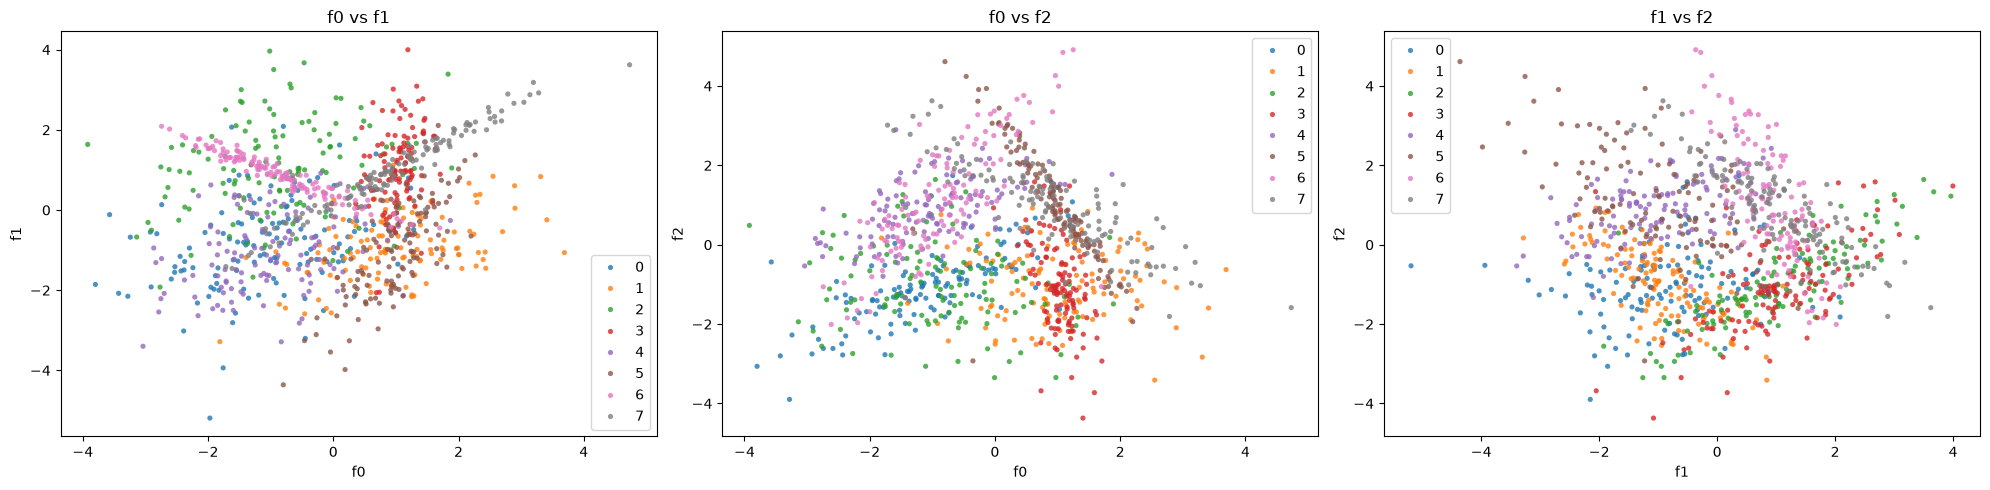

In [12]:
X, y = make_classification(n_samples=1_000, n_features=3, n_informative=3, n_redundant=0, n_classes=8,
                           n_clusters_per_class=1, flip_y=0.02, random_state=SEED)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    scatter(X[:, [i, j]], y, ax, f"f{i} vs f{j}", palette="tab10")
    ax.set_xlabel(f"f{i}")
    ax.set_ylabel(f"f{j}")
plt.tight_layout()
plt.show()

## 11. Szum w regresji: `reg_noisy`

Te same X i współczynniki, `noise=10` vs `noise=100` (odchylenie standardowe szumu dodawanego do targetu). Linia to prawdziwa zależność.

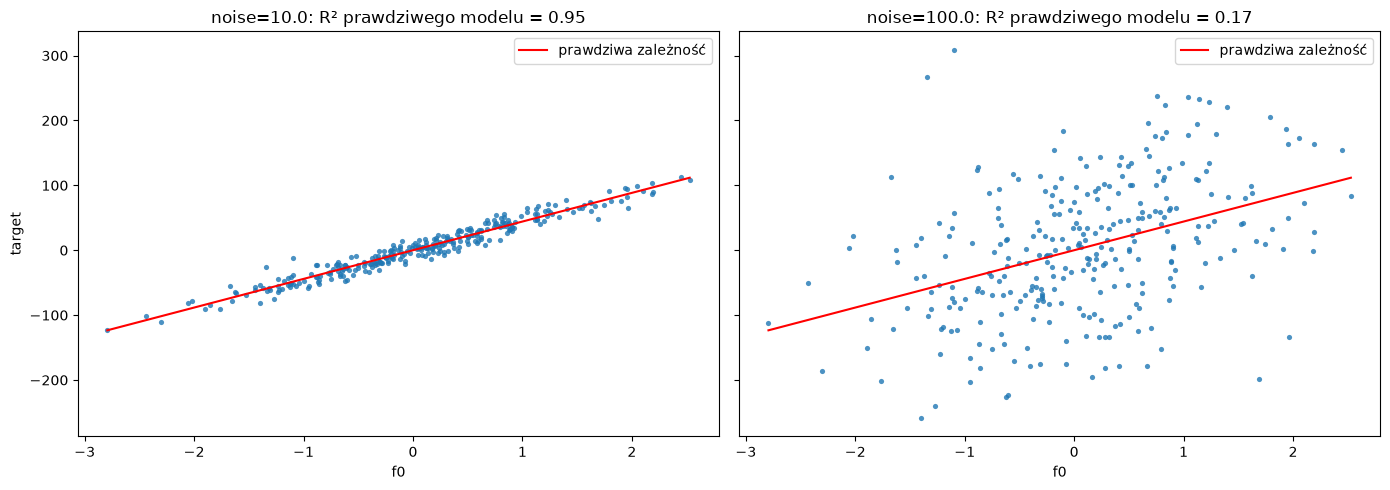

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, noise in zip(axes, [10.0, 100.0]):
    X, y, coef = make_regression(n_samples=300, n_features=1, n_informative=1, noise=noise, coef=True, random_state=SEED)
    sns.scatterplot(x=X[:, 0], y=y, s=14, alpha=0.8, linewidth=0, ax=ax)
    xs = np.linspace(X.min(), X.max(), 2)
    ax.plot(xs, coef * xs, color="red", label="prawdziwa zależność")
    r2 = 1 - np.var(y - coef * X[:, 0]) / np.var(y)
    ax.set_title(f"noise={noise}: R² prawdziwego modelu = {r2:.2f}")
    ax.set_xlabel("f0")
    ax.set_ylabel("target")
    ax.legend()
plt.tight_layout()
plt.show()

## 12. Współliniowość w regresji: `reg_collinear`

`effective_rank` generuje macierz cech o niskim rzędzie: kilka ukrytych kierunków odpowiada za prawie całą wariancję, więc cechy są silnie skorelowane.
Prawy wykres: udział wariancji w kolejnych wartościach osobliwych X. Bez `effective_rank` jest rozłożony równo, z `effective_rank=2` dominują pierwsze składowe.

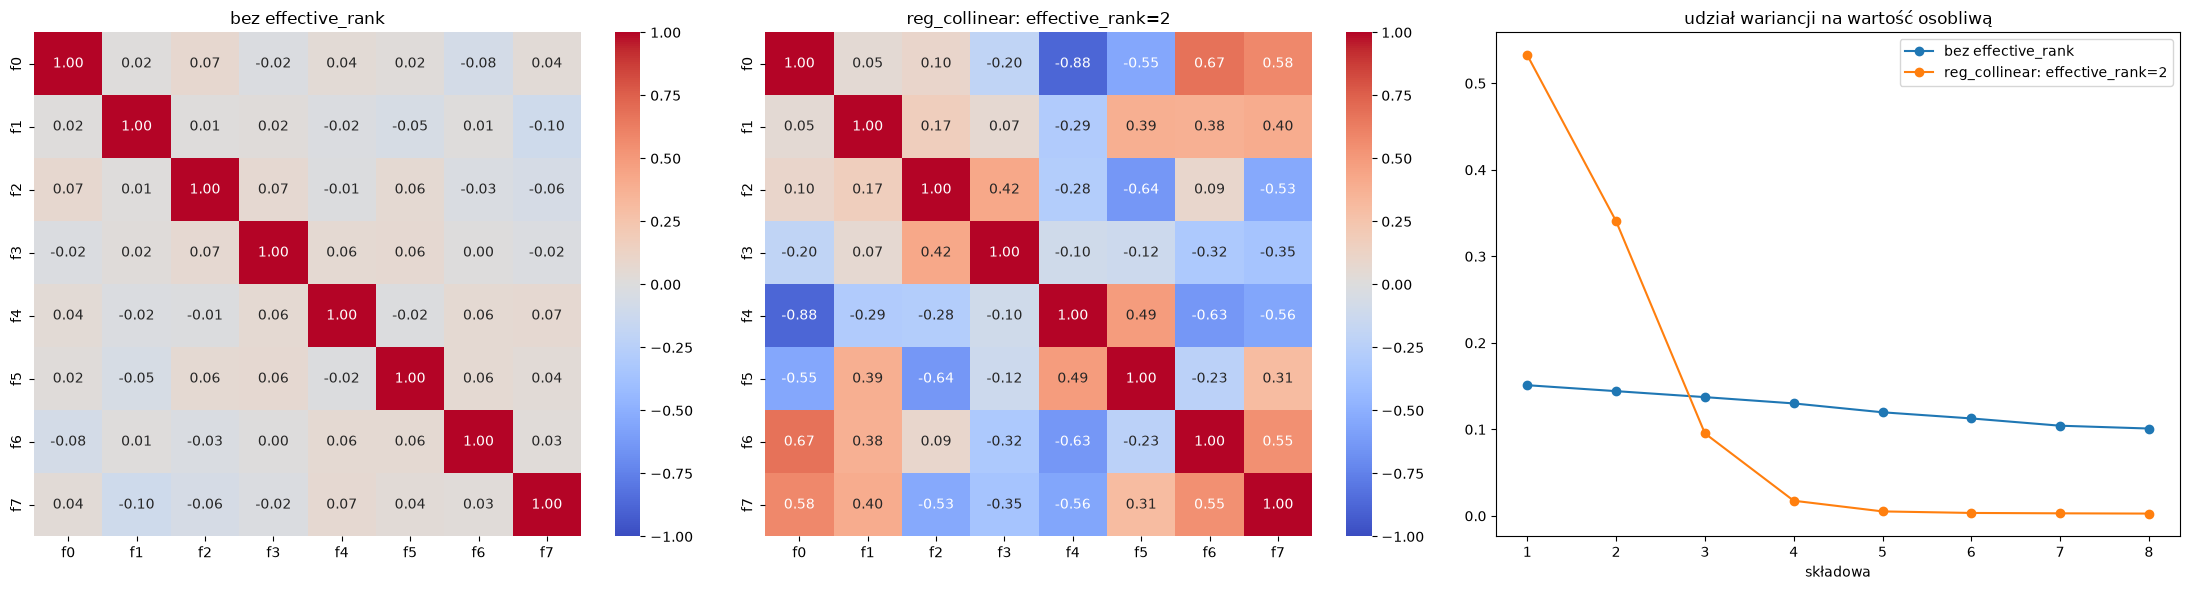

In [14]:
CONFIGS = {
    "bez effective_rank": dict(),
    "reg_collinear: effective_rank=2": dict(effective_rank=2, tail_strength=0.1),
}

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
for (name, cfg), ax in zip(CONFIGS.items(), axes):
    X, y = make_regression(n_samples=500, n_features=8, n_informative=4, noise=5.0, **cfg, random_state=SEED)
    sns.heatmap(pd.DataFrame(X).add_prefix("f").corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
    ax.set_title(name)
    s = np.linalg.svd(X - X.mean(0), compute_uv=False) ** 2
    axes[2].plot(range(1, len(s) + 1), s / s.sum(), marker="o", label=name)
axes[2].set_title("udział wariancji na wartość osobliwą")
axes[2].set_xlabel("składowa")
axes[2].legend()
plt.tight_layout()
plt.show()

## 13. Nieliniowa regresja: `reg_hard_nonlinear` (Friedman #1)

`y = 10·sin(π·x0·x1) + 20·(x2 − 0.5)² + 10·x3 + 5·x4 + szum`, a cechy od `x5` wzwyż to czysty szum.
Czerwona linia to średni target w przedziałach cechy. Górny rząd: Friedman #1 (`x2` daje parabolę, `x0` i `x1` działają tylko razem przez interakcję, `x5` nie ma wpływu). Dolny rząd: `make_regression` dla porównania, gdzie każda informatywna cecha ma liniowy wpływ.

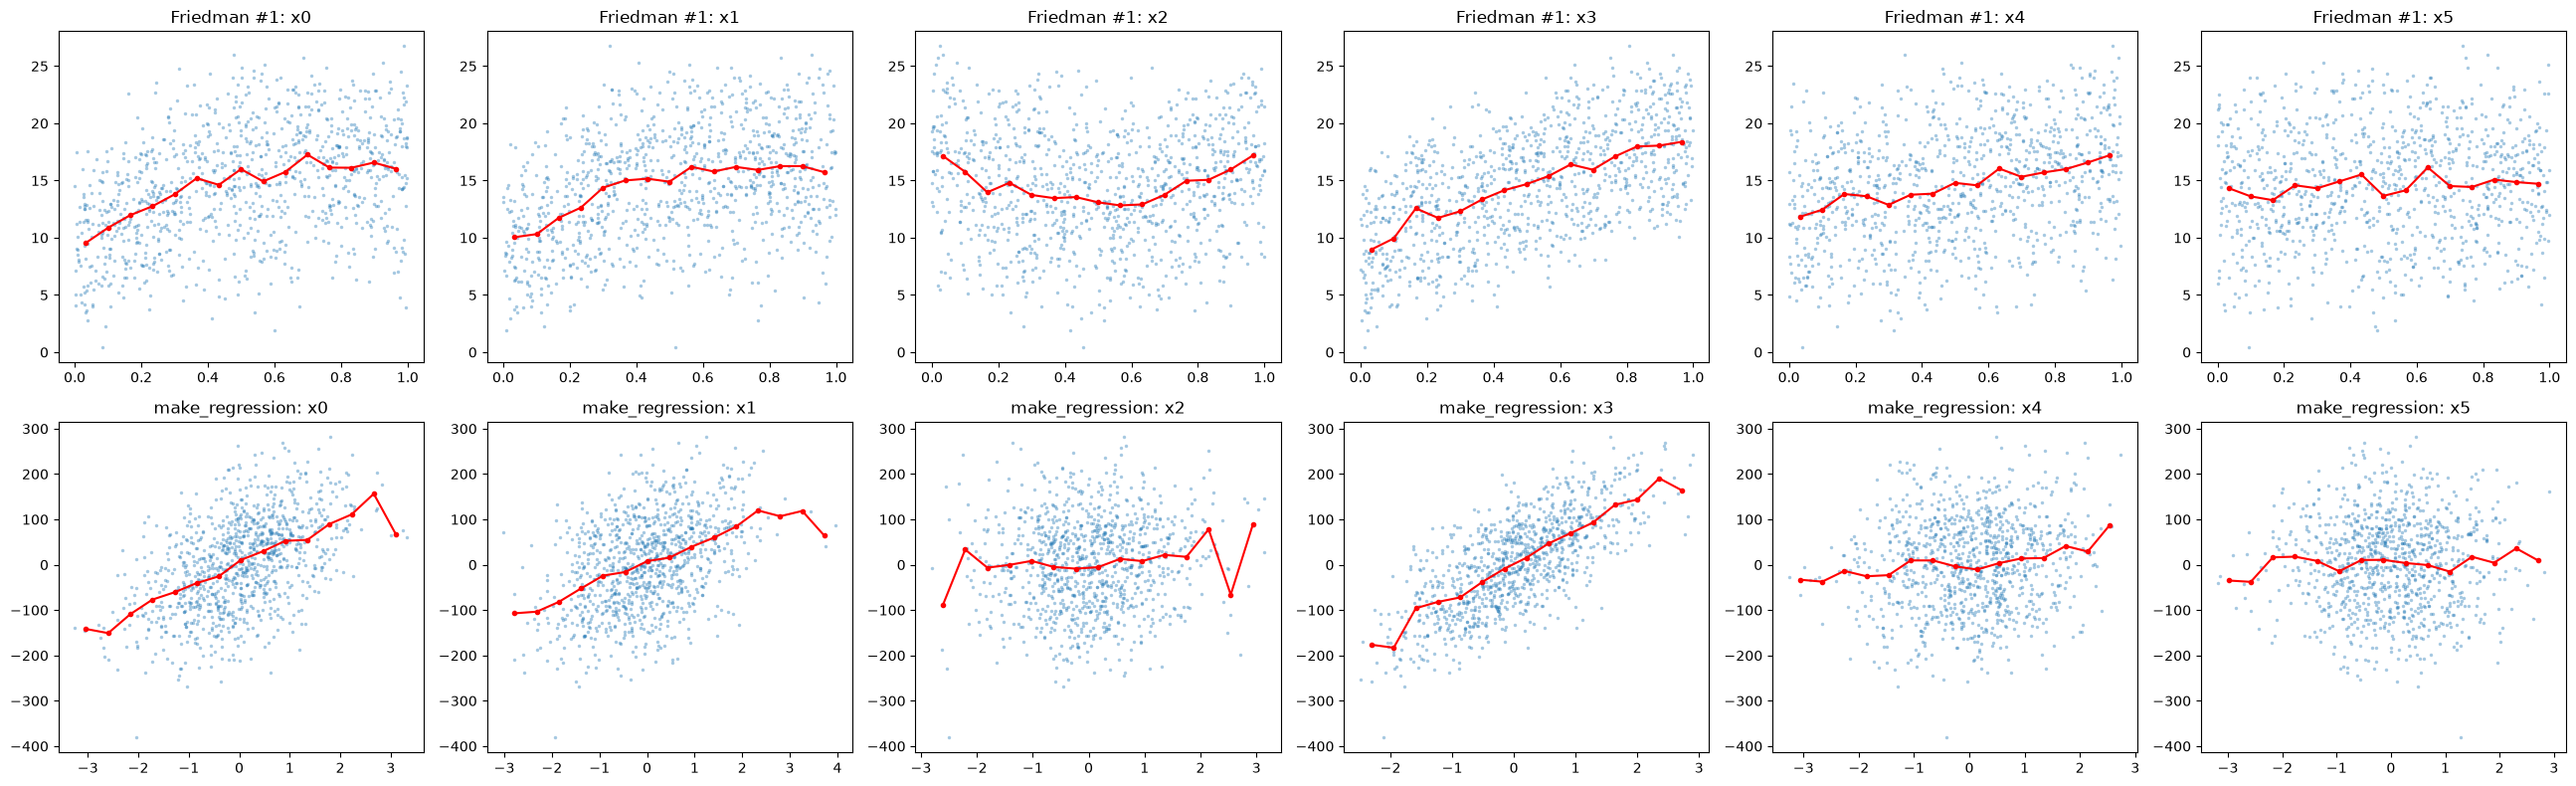

In [15]:
X_fr, y_fr = make_friedman1(n_samples=1_000, n_features=6, noise=1.0, random_state=SEED)
X_lin, y_lin = make_regression(n_samples=1_000, n_features=6, n_informative=5, noise=10.0, shuffle=False, random_state=SEED)

fig, axes = plt.subplots(2, 6, figsize=(26, 8))
for row, (X, y, name) in zip(axes, [(X_fr, y_fr, "Friedman #1"), (X_lin, y_lin, "make_regression")]):
    for j, ax in enumerate(row):
        sns.scatterplot(x=X[:, j], y=y, s=6, alpha=0.4, linewidth=0, ax=ax)
        means = pd.Series(y).groupby(pd.cut(X[:, j], bins=15), observed=True).mean()
        ax.plot([b.mid for b in means.index], means.values, color="red", marker="o", markersize=3)
        ax.set_title(f"{name}: x{j}")
        ax.set_xlabel("")
        ax.set_ylabel("")
plt.tight_layout()
plt.show()